Pour cette première étape d'exploration des données, nous analysons la distribution de la variable cible SalePrice. Cette étude préliminaire nous aide à comprendre la répartition des prix immobiliers, à détecter la présence de valeurs extrêmes, et à déterminer si des transformations seront nécessaires pour respecter les hypothèses des algorithmes de modélisation. Nous examinerons visuellement la distribution via un histogramme accompagné d'une courbe de densité (KDE), puis quantifierons son asymétrie et son aplatissement à l'aide des mesures statistiques de skewness et kurtosis.

In [95]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns  #Seaborn est une bibliothèque de visualisation de données basée sur Matplotlib.
from sklearn.preprocessing import LabelEncoder #LabelEncoder de scikit-learn est un outil de prétraitement pour encoder les variables catégorielles en valeurs numériques.


In [96]:
df = pd.read_csv('../dataset/raw/AmesHousing.csv')

In [97]:
print(f"Dimensions du dataset : {df.shape}")
print("-" * 30)
# Affiche un résumé des types et des valeurs nulles
df.info()

Dimensions du dataset : (2930, 82)
------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2930 entries, 0 to 2929
Data columns (total 82 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Order            2930 non-null   int64  
 1   PID              2930 non-null   int64  
 2   MS SubClass      2930 non-null   int64  
 3   MS Zoning        2930 non-null   object 
 4   Lot Frontage     2440 non-null   float64
 5   Lot Area         2930 non-null   int64  
 6   Street           2930 non-null   object 
 7   Alley            198 non-null    object 
 8   Lot Shape        2930 non-null   object 
 9   Land Contour     2930 non-null   object 
 10  Utilities        2930 non-null   object 
 11  Lot Config       2930 non-null   object 
 12  Land Slope       2930 non-null   object 
 13  Neighborhood     2930 non-null   object 
 14  Condition 1      2930 non-null   object 
 15  Condition 2      2930 non-null   object 



Pour cette première étape d'exploration des données, nous analysons la distribution de la variable cible SalePrice. Cette étude préliminaire nous aide à comprendre la répartition des prix immobiliers, à détecter la présence de valeurs extrêmes, et à déterminer si des transformations seront nécessaires pour respecter les hypothèses des algorithmes de modélisation. Nous examinerons visuellement la distribution via un histogramme accompagné d'une courbe de densité (KDE), puis quantifierons son asymétrie et son aplatissement à l'aide des mesures statistiques de skewness et kurtosis.



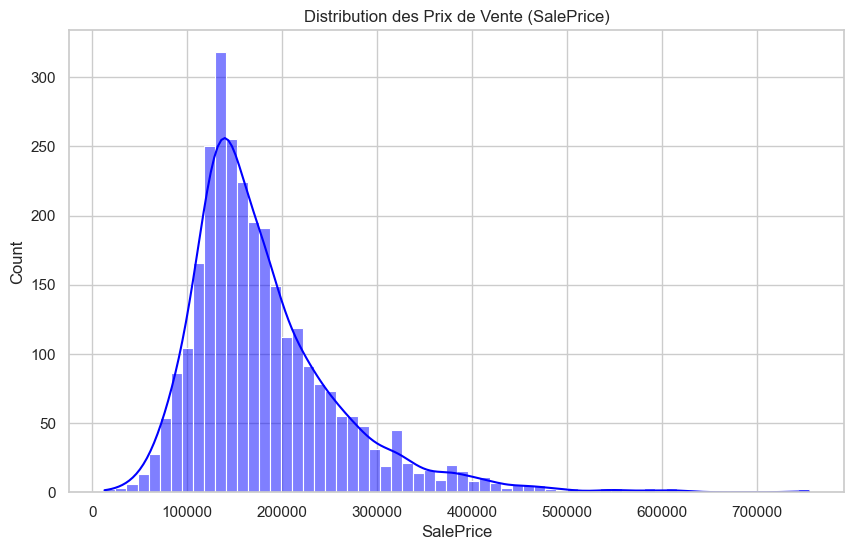

Skewness (Asymétrie) : 1.7435000757376466
Kurtosis (Aplatissement) : 5.118899951130896


In [98]:

sns.set(style="whitegrid") #Définit un thème spécifique avec fond blanc et grille

plt.figure(figsize=(10, 6))
sns.histplot(df['SalePrice'], kde=True, color='blue')
plt.title('Distribution des Prix de Vente (SalePrice)')
plt.show()

print(f"Skewness (Asymétrie) : {df['SalePrice'].skew()}")
print(f"Kurtosis (Aplatissement) : {df['SalePrice'].kurt()}")


Le graphique ci-dessus représente la distribution des prix de vente (SalePrice) sous forme d’un histogramme accompagné d’une courbe de densité (KDE). On observe que la majorité des biens immobiliers se vendent dans une plage de prix relativement basse à moyenne, tandis que peu de biens atteignent des prix très élevés. La distribution n’est pas symétrique : elle est étirée vers la droite, ce qui indique la présence de valeurs élevées rares. Cette observation est confirmée par la valeur positive de l’asymétrie (Skewness ≈ 1,74), montrant une distribution asymétrique à droite. De plus, la valeur élevée de l’aplatissement (Kurtosis ≈ 5,12) indique une distribution plus concentrée autour de la moyenne avec des valeurs extrêmes marquées. Cela signifie que le jeu de données contient des biens atypiques à prix très élevés, ce qui peut influencer les analyses et les modèles de prédiction.

Pour remédier à cette problématique, une transformation logarithmique de la variable cible SalePrice sera appliquée. Cette transformation permet de réduire l’asymétrie de la distribution, de limiter l’influence des valeurs extrêmes et de rapprocher les données d’une distribution plus proche de la normalité. En conséquence, les modèles de régression peuvent mieux apprendre les relations entre les caractéristiques du bien et le prix de vente, ce qui améliore la stabilité de l’entraînement ainsi que la précision des prédictions.

Skewness (log) : -0.014772659537224368
Kurtosis (log) : 1.5138180928006526


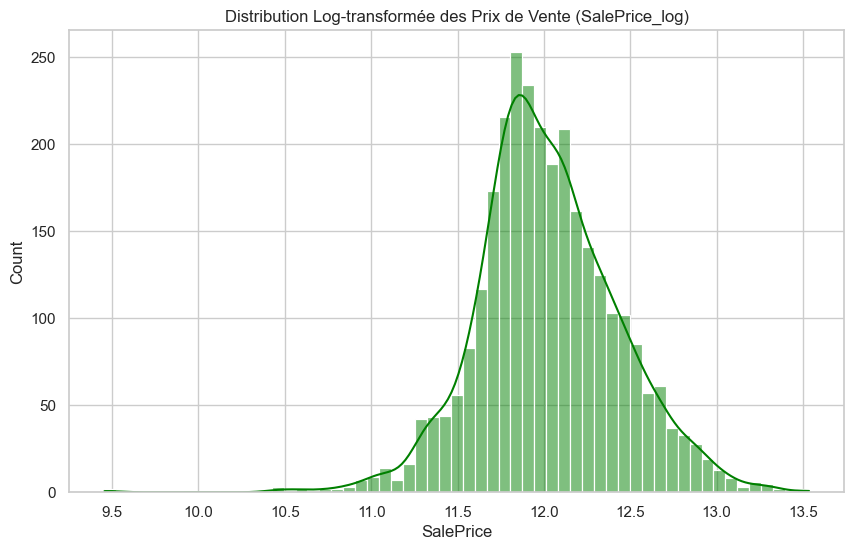

In [99]:


# Transformation Log
df["SalePrice"] = np.log1p(df["SalePrice"])
# Vérification 
print(f"Skewness (log) : {df['SalePrice'].skew()}")
print(f"Kurtosis (log) : {df['SalePrice'].kurt()}")

plt.figure(figsize=(10, 6))
sns.histplot(df['SalePrice'], kde=True, color='green')
plt.title('Distribution Log-transformée des Prix de Vente (SalePrice_log)')
plt.show()

La transformation logarithmique a significativement amélioré la distribution des prix de vente. La nouvelle skewness de -0.014 indique une asymétrie négligeable, démontrant que la distribution est désormais quasi-symétrique et bien plus proche d'une distribution normale. Quant à la kurtosis de 1.51, bien que légèrement supérieure à zéro, elle reste dans des limites acceptables pour la modélisation, signalant une distribution un peu plus pointue que la normale mais sans présence excessive de valeurs extrêmes. Ces métriques confirment l'efficacité de la transformation pour normaliser la variable cible en vue de l'application d'algorithmes de machine learning.


Nous allons maintenant analyser les relations entre le prix de vente et les différentes caractéristiques des propriétés. Pour cela, nous allons calculer la matrice de corrélation qui mesure les liens linéaires entre variables numériques. Cette analyse nous permettra d'identifier quelles caractéristiques influencent positivement le prix (corrélation positive), quelles variables sont indépendantes (corrélation nulle), et quels facteurs peuvent avoir un impact négatif sur la valeur immobilière (corrélation négative). Cette étape est essentielle pour comprendre les drivers de prix et sélectionner les variables les plus pertinentes pour la modélisation.

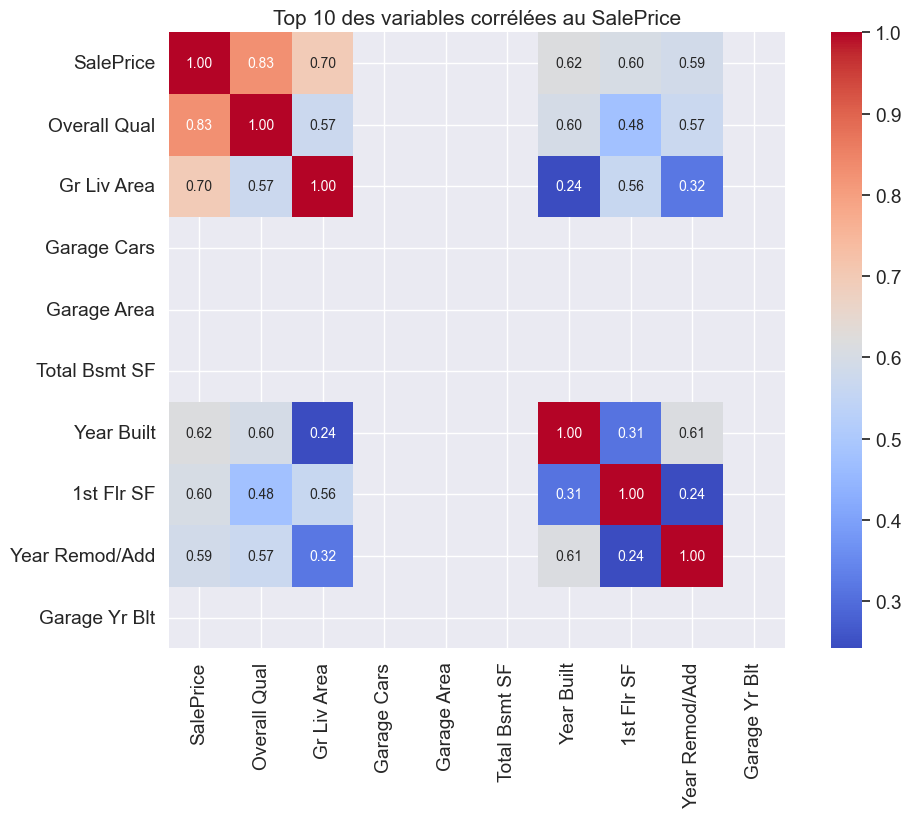

In [101]:
corr_matrix = df.select_dtypes(include=[np.number]).corr()

# Zoom sur les 10 variables les plus corrélées au Prix (SalePrice)
k = 10 
cols = corr_matrix.nlargest(k, 'SalePrice')['SalePrice'].index

plt.figure(figsize=(12, 8))
cm = np.corrcoef(df[cols].values.T)
sns.set(font_scale=1.25)
# Heatmap annotée
sns.heatmap(cm, 
           cbar=True,           # Affiche la barre de couleur
           annot=True,          # Affiche les valeurs dans les cases
           square=True,         # Cases carrées
           fmt='.2f',           # Format à 2 décimales
           annot_kws={'size': 10},  # Taille du texte des annotations
           yticklabels=cols.values,  # Noms sur l'axe Y
           xticklabels=cols.values,  # Noms sur l'axe X  
           cmap='coolwarm')     # Palette de couleurs (bleu=froid, rouge=chaud)

plt.title('Top 10 des variables corrélées au SalePrice')
plt.show()

Interprétation des résultats :

L'analyse montre que la qualité globale de la maison est le facteur le plus influent sur le prix (+0.83). Plus une maison est jugée de bonne qualité, plus son prix est élevé. La surface habitable vient en seconde position (+0.70) : plus la maison est spacieuse, plus elle est chère.

Mais on a pas assez de donnees pour completer la grille donc on devra y remedier dans l'etape de pretraitement

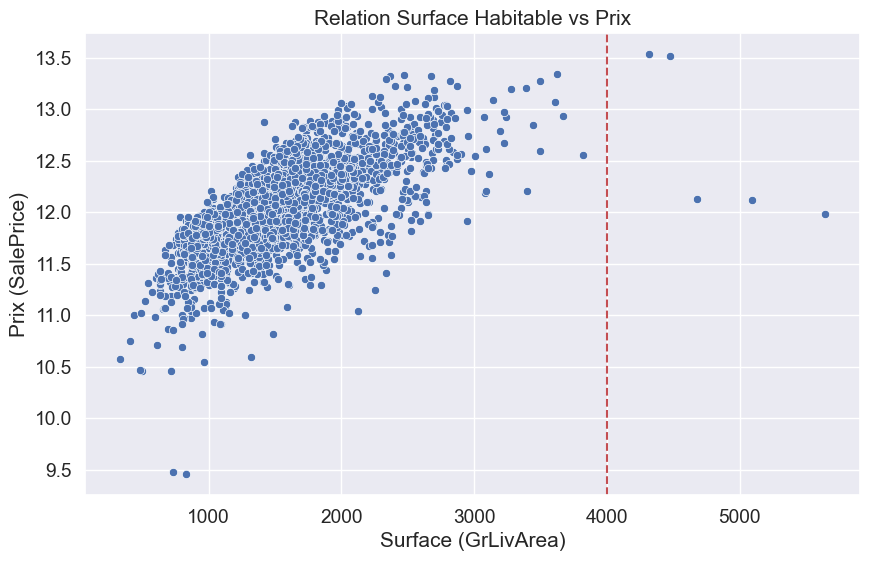

In [ ]:
# GrLivArea = Surface habitable au dessus du sol
plt.figure(figsize=(10, 6))
sns.scatterplot(x=df['Gr Liv Area'], y=df['SalePrice'])
plt.title('Relation Surface Habitable vs Prix')
plt.xlabel('Surface (GrLivArea)')
plt.ylabel('Prix (SalePrice)')

# On trace des lignes qui nous aident à repérer les anomalies
plt.axvline(x=4000, color='r', linestyle='--') # Limite suspecte souvent observée
plt.show()


Le graphique confirme la corrélation positive entre surface et prix mais révèle des anomalies importantes : certaines propriétés très spacieuses (≥4000 pieds²) présentent des prix étonnamment bas. Ces valeurs extrêmes, invisibles dans la simple analyse de corrélation, pourraient perturber les modèles prédictifs et nécessitent un traitement spécifique.






 Maintenant nous allons créer un boxplot afin d’analyser l’influence de l’exposition du sous-sol sur le prix de vente des biens immobiliers, nous avons représenté la distribution des prix selon les différentes catégories d’exposition du sous-sol. L’exposition du sous-sol reflète le degré d’ouverture vers l’extérieur et la luminosité naturelle dont il bénéficie, ce qui peut impacter le confort et la valeur perçue du logement. Le diagramme en boîte ci-dessous permet de comparer les prix de vente en fonction de chaque niveau d’exposition et d’identifier d’éventuelles différences significatives entre les catégories.

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_15636\3817961872.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Bsmt Exposure', y='SalePrice', data=df, palette='viridis')


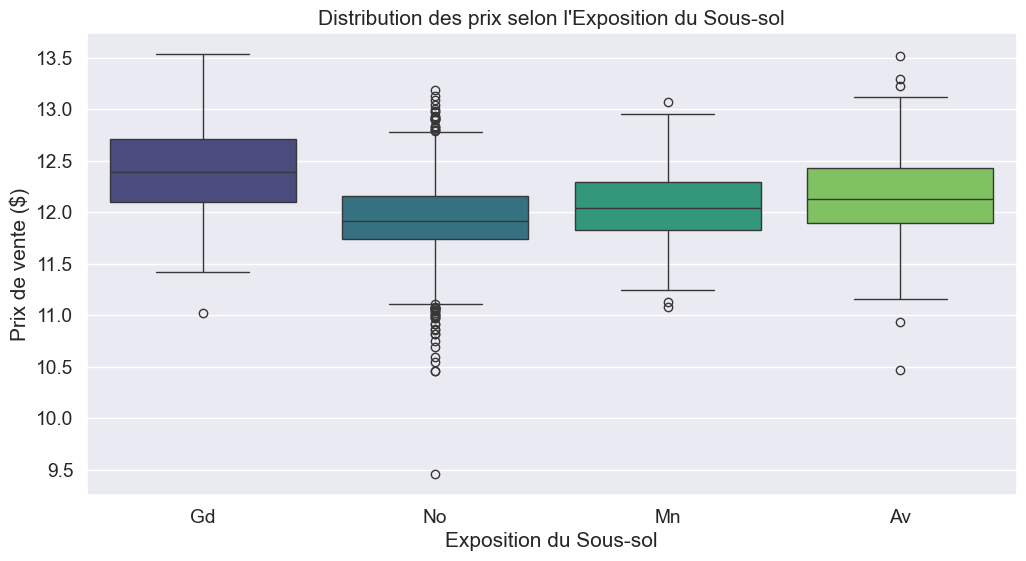

In [ ]:
plt.figure(figsize=(12, 6))
sns.boxplot(x='Bsmt Exposure', y='SalePrice', data=df, palette='viridis')
plt.title('Distribution des prix selon l\'Exposition du Sous-sol')
plt.xlabel('Exposition du Sous-sol')
plt.ylabel('Prix de vente ($)')
plt.show()



Le boxplot montre que l’exposition du sous-sol a un impact notable sur le prix de vente des logements. Les biens disposant d’une bonne exposition (Gd) présentent globalement les prix médians les plus élevés, ce qui suggère que la luminosité et l’ouverture du sous-sol sont des critères valorisés sur le marché immobilier. À l’inverse, les logements sans exposition du sous-sol (No) affichent les prix les plus bas et une plus grande dispersion, avec plusieurs valeurs atypiques, indiquant une qualité et une attractivité variables. Les catégories Mn et Av occupent une position intermédiaire, avec des prix médians relativement proches mais inférieurs à ceux des sous-sols bien exposés. Ces observations confirment que l’amélioration de l’exposition du sous-sol peut contribuer à augmenter la valeur globale d’un bien immobilier

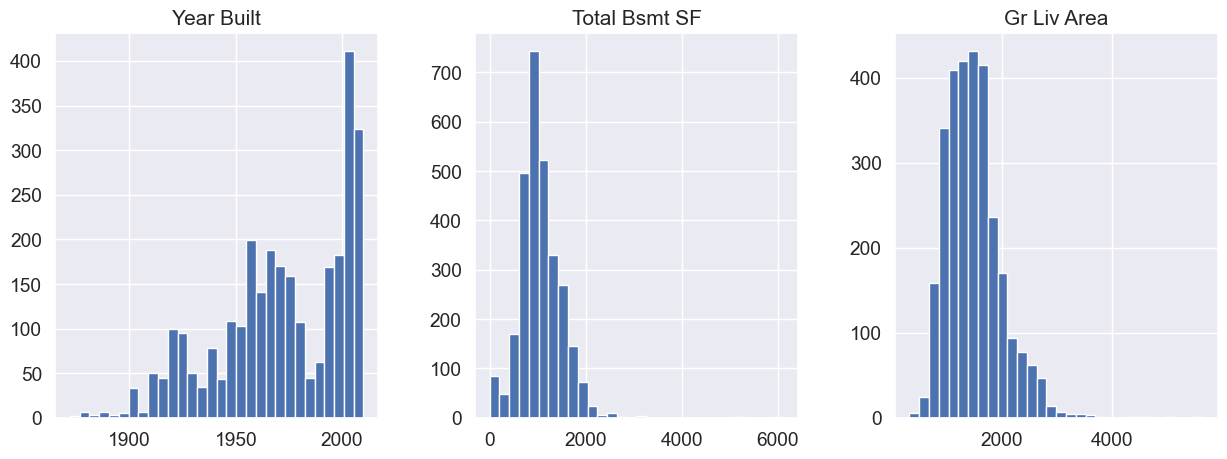

In [ ]:
# Afficher l'histogramme de quelques variables clés: Année de construction ,Surface totale du sous-sol ,Surface habitable
cols_to_check = ['Year Built', 'Total Bsmt SF', 'Gr Liv Area']
df[cols_to_check].hist(bins=30, figsize=(15, 5), layout=(1, 3))
plt.show()


Les histogrammes montrent que la majorité des logements ont été construits après les années 1900. Les variables Total Bsmt SF et Gr Liv Area présentent des distributions asymétriques à droite, avec une concentration sur des valeurs moyennes et quelques valeurs extrêmes. Ces observations indiquent que les surfaces peuvent fortement influencer le prix de vente et nécessitent un traitement des valeurs atypiques lors de l’analyse.

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_15636\1153606772.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Overall Qual', y='SalePrice', data=df, palette='viridis')


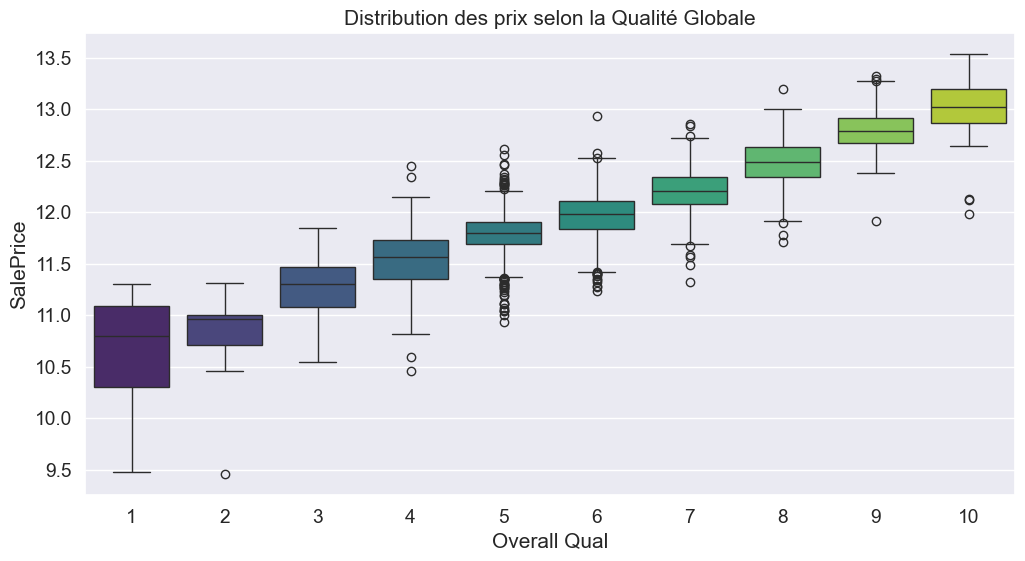

In [105]:
# OverallQual : Note de 1 à 10 de la qualité globale
plt.figure(figsize=(12, 6))
sns.boxplot(x='Overall Qual', y='SalePrice', data=df, palette='viridis')
plt.title('Distribution des prix selon la Qualité Globale')
plt.show()


Le boxplot met en évidence une relation fortement positive entre la qualité globale du logement (OverallQual) et le prix de vente. Plus la note de qualité augmente, plus le prix médian du bien est élevé, avec une progression régulière de 1 à 10. Les logements de faible qualité présentent des prix plus bas, tandis que ceux de haute qualité affichent des prix élevés. Cela confirme que la qualité globale est un facteur déterminant dans la valorisation des biens immobiliers.




Le prétraitement des données

In [106]:

# --- 1. Sauvegarde de l'ID ---
# On garde les ID pour la soumission finale, mais ils ne servent pas à prédire
train_ID = df['PID']
df.drop("PID", axis = 1, inplace = True)


In [107]:
# Calcul du pourcentage de données manquantes
total = df.isnull().sum().sort_values(ascending=False)
percent = (df.isnull().sum() / df.isnull().count()).sort_values(ascending=False)
missing_data = pd.concat([total, percent], axis=1, keys=['Total', 'Percent'])

# Affiche les 20 pires colonnes
print(missing_data.head(20))


                Total   Percent
Pool QC          2917  0.995563
Misc Feature     2824  0.963823
Alley            2732  0.932423
Fence            2358  0.804778
Mas Vnr Type     1775  0.605802
Fireplace Qu     1422  0.485324
Lot Frontage      490  0.167235
Garage Yr Blt     159  0.054266
Garage Cond       159  0.054266
Garage Qual       159  0.054266
Garage Finish     159  0.054266
Garage Type       157  0.053584
Bsmt Exposure      83  0.028328
BsmtFin Type 2     81  0.027645
Bsmt Cond          80  0.027304
Bsmt Qual          80  0.027304
BsmtFin Type 1     80  0.027304
Mas Vnr Area       23  0.007850
Bsmt Full Bath      2  0.000683
Bsmt Half Bath      2  0.000683


In [108]:
df.head()

,Order,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,Utilities,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,1,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2010,WD,Normal,12.278398
1,2,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,11.561725
2,3,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,12.055256
3,4,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,12.404928
4,5,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,12.154258


Cette analyse identifie les colonnes avec des valeurs manquantes dans notre jeu de données. Le tableau révèle que certaines caractéristiques comme Pool QC (qualité de la piscine), Misc Feature (équipements divers) et Alley (allée) présentent des taux de valeurs manquantes très élevés, dépassant 90%. Ces champs correspondent souvent à des aménagements optionnels que la majorité des propriétés ne possèdent pas. À l'inverse, d'autres variables comme Lot Frontage (front de lot) et les caractéristiques du garage montrent des taux de complétion plus élevés, avec moins de 20% de données manquantes. Cette analyse nous guidera dans les décisions de traitement des données manquantes.

Les valeurs manquantes (NaN) de ces colonnes correspondent à l'absence des caractéristiques concernées et non à des données inconnues, ce qui justifie leur remplacement par la valeur zéro.

In [ ]:
cols_fill_0 = [
    # GARAGE 
    'Garage Yr Blt',       # Année de construction du garage
    'Garage Area',         # Surface du garage en pieds carrés
    'Garage Cars',         # Nombre de voitures que le garage peut accueillir
    
    # SOUS-SOL (BASEMENT)
    'BsmtFin SF 1',        # Surface finie du sous-sol (type 1 de finition)
    'BsmtFin SF 2',        # Surface finie du sous-sol (type 2 de finition)
    'Bsmt Unf SF',         # Surface non finie (brute) du sous-sol
    'Total Bsmt SF',       # Surface totale du sous-sol (finie + non finie)
    'Bsmt Full Bath',      # Nombre de salles de bain complètes au sous-sol
    'Bsmt Half Bath'       # Nombre de demi-salles de bain au sous-sol
]

for col in cols_fill_0:
    df[col] = df[col].fillna(0)



In [110]:
df.head()


,Order,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,Utilities,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,1,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2010,WD,Normal,12.278398
1,2,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,11.561725
2,3,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,12.055256
3,4,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,12.404928
4,5,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,12.154258


Les colonnes catégorielles suivantes contiennent des NaN qui représentent l'absence des équipements correspondants. Nous les remplaçons par la valeur 'None' pour préserver cette information.

In [111]:


cols_fill_none = [
    'Pool QC',         # Qualité de la piscine
    'Misc Feature',    # Équipement divers
    'Alley',           # Allée d'accès
    'Fence',           # Clôture
    'Fireplace Qu',    # Qualité de la cheminée
    'Garage Type',     # Type de garage
    'Garage Finish',   # Finition du garage
    'Garage Qual',     # Qualité du garage
    'Garage Cond',     # État du garage
    'Bsmt Qual',       # Qualité du sous-sol
    'Bsmt Cond',       # État du sous-sol
    'Bsmt Exposure',   # Exposition du sous-sol
    'BsmtFin Type 1',  # Type de finition sous-sol (zone 1)
    'BsmtFin Type 2'   # Type de finition sous-sol (zone 2)
]

for col in cols_fill_none:
    df[col] = df[col].fillna('None')


Pour Lot Frontage les valeurs manquantes sont complétées par la médiane calculée au niveau du quartier (Neighborhood) et la médiane globale si un quartier n’a aucune valeur disponible.

In [112]:
# Calculer d'abord la médiane globale pour l'utiliser Si un quartier n'a AUCUNE valeur de Lot Frontage (tous NaN)
global_median = df["Lot Frontage"].median()

# Appliquer la transformation avec fallback sur la médiane globale
df["Lot Frontage"] = df.groupby("Neighborhood")["Lot Frontage"].transform(
    lambda x: x.fillna(x.median() if not x.isnull().all() else global_median))









Nous examinons maintenant la relation entre la surface habitable et le prix de vente à l'aide d'un graphique de dispersion. Cette visualisation nous permettra de vérifier la cohérence de la relation linéaire observée dans la matrice de corrélation et d'identifier d'éventuelles valeurs aberrantes, notamment les propriétés présentant des surfaces exceptionnellement élevées.

Ces caractéristiques catégorielles comportent peu de valeurs manquantes réelles. Nous les complétons par la modalité la plus fréquente du dataset, une méthode simple qui préserve la distribution des données sans introduire de valeurs artificielles, permettant ainsi de conserver toutes les observations.

In [113]:

cols_remaining = [
    'MS Zoning',        # Type de zone municipale
    'Electrical',       # Système électrique
    'Kitchen Qual',    # Qualité de la cuisine
    'Exterior 1st',    # Revêtement extérieur principal
    'Exterior 2nd',    # Revêtement extérieur secondaire
    'Sale Type',       # Type de vente
    'Mas Vnr Type'     # Type de placage de brique/pierre
]
for col in cols_remaining:
    df[col] = df[col].fillna(df[col].mode()[0]) # mode()[0] prend la 1ère valeur la plus fréquente si il existe plusieurs 


In [114]:
# --- 6. Vérification finale ---
print("Valeurs manquantes restantes :", df.isnull().sum().max())

Valeurs manquantes restantes : 23


In [116]:

# 1. MasVnrArea : On remplit par 0
df['Mas Vnr Area'] = df['Mas Vnr Area'].fillna(0)

# 3. Vérification 
nan_count = df.isnull().sum().sum()
print(f"Nombre total de NaN restants : {nan_count}")



Nombre total de NaN restants : 0


In [119]:
# Calcul du pourcentage de données manquantes
total = df.isnull().sum().sort_values(ascending=False)
percent = (df.isnull().sum() / df.isnull().count()).sort_values(ascending=False)
missing_data = pd.concat([total, percent], axis=1, keys=['Total', 'Percent'])

# Affiche les 20 pires colonnes
print(missing_data.head(20))

              Total  Percent
Order             0      0.0
MS SubClass       0      0.0
MS Zoning         0      0.0
Lot Frontage      0      0.0
Lot Area          0      0.0
Street            0      0.0
Alley             0      0.0
Lot Shape         0      0.0
Land Contour      0      0.0
Utilities         0      0.0
Lot Config        0      0.0
Land Slope        0      0.0
Neighborhood      0      0.0
Condition 1       0      0.0
Condition 2       0      0.0
Bldg Type         0      0.0
House Style       0      0.0
Overall Qual      0      0.0
Overall Cond      0      0.0
Year Built        0      0.0


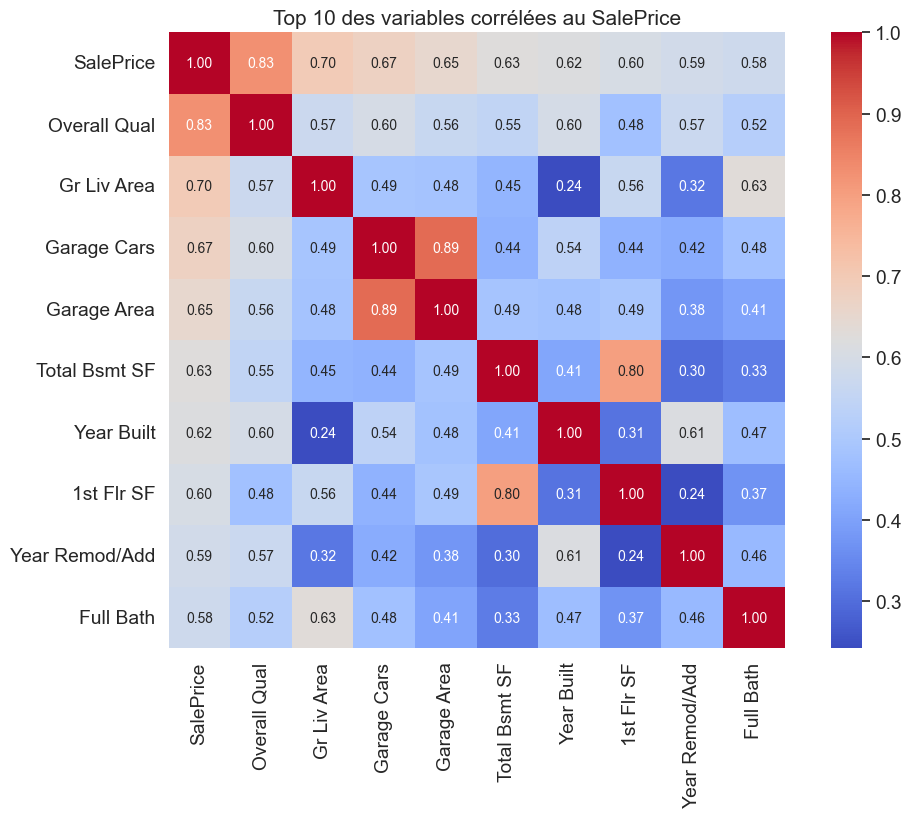

In [115]:
corr_matrix = df.select_dtypes(include=[np.number]).corr()

# Zoom sur les 10 variables les plus corrélées au Prix (SalePrice)
k = 10 
cols = corr_matrix.nlargest(k, 'SalePrice')['SalePrice'].index

plt.figure(figsize=(12, 8))
cm = np.corrcoef(df[cols].values.T)
sns.set(font_scale=1.25)
# Heatmap annotée
sns.heatmap(cm, 
           cbar=True,           # Affiche la barre de couleur
           annot=True,          # Affiche les valeurs dans les cases
           square=True,         # Cases carrées
           fmt='.2f',           # Format à 2 décimales
           annot_kws={'size': 10},  # Taille du texte des annotations
           yticklabels=cols.values,  # Noms sur l'axe Y
           xticklabels=cols.values,  # Noms sur l'axe X  
           cmap='coolwarm')     # Palette de couleurs (bleu=froid, rouge=chaud)

plt.title('Top 10 des variables corrélées au SalePrice')
plt.show()

Interprétation des résultats :

L'analyse montre que la qualité globale de la maison est le facteur le plus influent sur le prix (+0.83). Plus une maison est jugée de bonne qualité, plus son prix est élevé. La surface habitable vient en seconde position (+0.70) : plus la maison est spacieuse, plus elle est chère.

Le garage a également un impact important, à la fois par sa capacité (+0.67) et sa surface (+0.65). Les caractéristiques spatiales comme le sous-sol (+0.63) et le premier étage (+0.60) contribuent aussi significativement à la valeur.

Enfin, l'âge de la propriété joue un rôle : les maisons plus récentes (+0.62) ou rénovées récemment (+0.59) ont des prix plus élevés, tout comme celles avec plus de salles de bain complètes (+0.58).

La qualité globale des maisons a un impact direct et puissant sur leur prix. Plus la note est élevée (sur 10), plus le prix grimpe, surtout à partir de 6/10. Les maisons de qualité 9 ou 10 peuvent atteindre des prix très élevés, tandis que celles de faible qualité restent dans des fourchettes basses. C'est le facteur le plus important pour estimer la valeur d'un bien.

Nous procédons au nettoyage des valeurs aberrantes en supprimant les propriétés présentant une incohérence économique manifeste : celles dont la surface habitable dépasse 4000 pieds carrés tout en étant vendues à moins de 300 000 $. Ces observations, qui contredisent la logique immobilière de base (une grande surface devrait normalement se traduire par un prix plus élevé), risqueraient de biaiser significativement nos modèles prédictifs et nos analyses statistiques.

In [117]:
taille_initiale = df.shape

# Suppression des outliers (Grande surface mais petit prix)
df = df.drop(df[(df['Gr Liv Area'] > 4000) & (df['SalePrice'] < 300000)].index)

# Affichage des tailles avant/après
print(f"Taille initiale du dataset : {taille_initiale}")
print(f"Nouvelle taille du dataset : {df.shape}")
print(f"Nombre d'observations supprimées : {taille_initiale[0] - df.shape[0]}")

Taille initiale du dataset : (2930, 81)
Nouvelle taille du dataset : (2925, 81)
Nombre d'observations supprimées : 5


In [118]:
df.head()

,Order,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,Utilities,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,1,20,RL,141.0,31770,Pave,None,IR1,Lvl,AllPub,...,0,None,None,None,0,5,2010,WD,Normal,12.278398
1,2,20,RH,80.0,11622,Pave,None,Reg,Lvl,AllPub,...,0,None,MnPrv,None,0,6,2010,WD,Normal,11.561725
2,3,20,RL,81.0,14267,Pave,None,IR1,Lvl,AllPub,...,0,None,None,Gar2,12500,6,2010,WD,Normal,12.055256
3,4,20,RL,93.0,11160,Pave,None,Reg,Lvl,AllPub,...,0,None,None,None,0,4,2010,WD,Normal,12.404928
4,5,60,RL,74.0,13830,Pave,None,IR1,Lvl,AllPub,...,0,None,MnPrv,None,0,3,2010,WD,Normal,12.154258


Nous allons maintenant créer de nouvelles variables synthétiques qui captureront mieux l'information utile, tout en réduisant la dimensionnalité du dataset. L'objectif est d'identifier et de générer des caractéristiques ayant une forte corrélation avec le prix de vente, afin d'améliorer la performance des modèles prédictifs tout en allégeant la complexité des données

In [ ]:
# 1. Création de la surface totale (Combinaison des surfaces pour obtenir une métrique plus représentative)
df['TotalSF'] = df['Total Bsmt SF'] + df['1st Flr SF'] + df['2nd Flr SF']

# 2. Simplification de certaines variables (Transformation de variables continues en indicateurs binaires)
# Exemple : Y a-t-il une piscine ? (Oui/Non) au lieu de la qualité
df['HasPool'] = df['Pool Area'].apply(lambda x: 1 if x > 0 else 0)

# 3. RECODAGE DES VARIABLES CATÉGORIELLES MASQUÉES
# Certaines variables numériques sont en réalité des codes catégoriels (MSSubClass (Type de logement : 20, 30, 40...))
# Conversion en type string pour traitement approprié dans les modèles

df['MS SubClass'] = df['MS SubClass'].apply(str)
df['Overall Cond'] = df['Overall Cond'].astype(str) 
df['Yr Sold'] = df['Yr Sold'].astype(str)
df['Mo Sold'] = df['Mo Sold'].astype(str)


In [122]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2925 entries, 0 to 2929
Data columns (total 83 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Order            2925 non-null   int64  
 1   MS SubClass      2925 non-null   object 
 2   MS Zoning        2925 non-null   object 
 3   Lot Frontage     2925 non-null   float64
 4   Lot Area         2925 non-null   int64  
 5   Street           2925 non-null   object 
 6   Alley            2925 non-null   object 
 7   Lot Shape        2925 non-null   object 
 8   Land Contour     2925 non-null   object 
 9   Utilities        2925 non-null   object 
 10  Lot Config       2925 non-null   object 
 11  Land Slope       2925 non-null   object 
 12  Neighborhood     2925 non-null   object 
 13  Condition 1      2925 non-null   object 
 14  Condition 2      2925 non-null   object 
 15  Bldg Type        2925 non-null   object 
 16  House Style      2925 non-null   object 
 17  Overall Qual     29

Pour intégrer les variables catégorielles dans nos modèles, nous devons les convertir en format numérique. Nous utilisons deux techniques : le Label Encoding pour les échelles ordonnées (qualités, conditions) et le One-Hot Encoding pour les catégories sans hiérarchie. Cette transformation préserve la structure sémantique des données tout en les rendant exploitables par les algorithmes d'apprentissage.

In [ ]:


# A. Label Encoding pour les variables avec un ordre (Qualité)
cols_ordinal = ('Fireplace Qu', 'Bsmt Qual', 'Bsmt Cond', 'Garage Qual', 'Garage Cond', 
                'Exter Qual', 'Exter Cond','Heating QC', 'Pool QC', 'Kitchen Qual', 'BsmtFin Type 1', 
                'BsmtFin Type 2', 'Functional', 'Fence', 'Bsmt Exposure', 'Garage Finish', 'Land Slope',
                'Lot Shape', 'Paved Drive', 'Street', 'Alley', 'Central Air', 'MS SubClass', 'Overall Cond', 
                'Yr Sold', 'Mo Sold')

# On applique l'encodeur
for c in cols_ordinal:
    lbl = LabelEncoder() 
    lbl.fit(list(df[c].values)) 
    df[c] = lbl.transform(list(df[c].values))

print(f"Shape après Label Encoding: {df.shape}")

# B. One-Hot Encoding pour tout le reste (Quartier, Type de toit...)
# pandas a une fonction get_dummies qui transforme des variables catégorielles en variables numériques
df = pd.get_dummies(df)

print(f"Shape après One-Hot Encoding (Final): {df.shape}")


Shape après Label Encoding: (2925, 83)
Shape après One-Hot Encoding (Final): (2925, 234)


In [124]:
df.head()

,Order,MS SubClass,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Slope,Overall Qual,Overall Cond,...,Sale Type_New,Sale Type_Oth,Sale Type_VWD,Sale Type_WD,Sale Condition_Abnorml,Sale Condition_AdjLand,Sale Condition_Alloca,Sale Condition_Family,Sale Condition_Normal,Sale Condition_Partial
0,1,5,141.0,31770,1,1,0,0,6,4,...,False,False,False,True,False,False,False,False,True,False
1,2,5,80.0,11622,1,1,3,0,5,5,...,False,False,False,True,False,False,False,False,True,False
2,3,5,81.0,14267,1,1,0,0,6,5,...,False,False,False,True,False,False,False,False,True,False
3,4,5,93.0,11160,1,1,3,0,7,4,...,False,False,False,True,False,False,False,False,True,False
4,5,10,74.0,13830,1,1,0,0,5,4,...,False,False,False,True,False,False,False,False,True,False


In [125]:
# Sauvegarde dans data/processed
df.to_csv('../dataset/traite/train_cleaned.csv', index=False)
print("Fichier nettoyé sauvegardé avec succès.")


Fichier nettoyé sauvegardé avec succès.


Cette première partie du projet a permis de réaliser une analyse exploratoire et un prétraitement complet du dataset immobilier AmesHousing. Les principales caractéristiques des données ont été étudiées, et les valeurs manquantes ont été traitées selon la nature des variables. De plus, les valeurs aberrantes ont été identifiées et supprimées afin de limiter leur influence sur les futures prédictions.

À l’issue de ces étapes, le jeu de données obtenu est propre, cohérent et prêt à être exploité par des algorithmes de machine learning. Ce travail de préparation constitue une étape essentielle pour garantir des résultats fiables et stables lors de l’entraînement des modèles. La suite du projet consistera à mettre en place et à comparer différents modèles de machine learning afin de prédire le prix de vente des biens immobiliers.